In [ ]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from statsmodels.tsa.seasonal import seasonal_decompose

In [ ]:
# Load Dataset
df = pd.read_csv("Sample - Superstore.csv", encoding="latin1")
print(df.head())

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [ ]:
print(df.shape)

print(df.info())

print(df.isnull().sum())

(9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 1

In [ ]:
# Convert Order Date to Datetime

df["Order Date"] = pd.to_datetime(df["Order Date"])

# Monthly Sales

monthly_sales = (
    df.groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
      .sum()
      .reset_index()
)

print(monthly_sales.head())
print(monthly_sales.shape)

  Order Date      Sales
0 2014-01-31  14236.895
1 2014-02-28   4519.892
2 2014-03-31  55691.009
3 2014-04-30  28295.345
4 2014-05-31  23648.287
(48, 2)


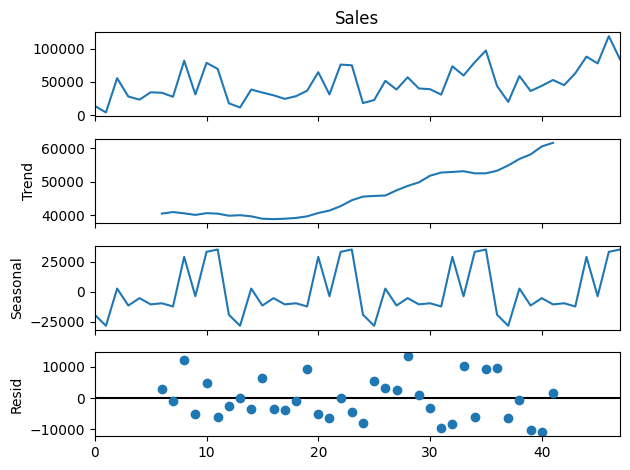

In [ ]:
# Seasonal Decomposition

decomposition = seasonal_decompose(
    monthly_sales["Sales"],
    model="additive",
    period=12
)

decomposition.plot()

plt.show()

In [ ]:
# Train-Test Split

train = monthly_sales.iloc[:36]
test = monthly_sales.iloc[36:]

print("Training Data :", len(train))
print("Testing Data  :", len(test))

Training Data : 36
Testing Data  : 12


In [ ]:
# Build SARIMA Model

sarima_model = SARIMAX(
    train["Sales"],
    order=(1,0,0),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit()

print(sarima_fit.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


                                      SARIMAX Results                                       
Dep. Variable:                                Sales   No. Observations:                   36
Model:             SARIMAX(1, 0, 0)x(1, 1, [1], 12)   Log Likelihood                -118.801
Date:                              Tue, 28 Jul 2026   AIC                            245.602
Time:                                      16:38:48   BIC                            247.194
Sample:                                           0   HQIC                           244.599
                                               - 36                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2891      0.370     -0.781      0.435      -1.014       0.436
ar.S.L12      -1.72

In [ ]:
# Forecast Test Data

predictions = sarima_fit.forecast(steps=len(test))

print(predictions)

36   -11580.120372
37    29383.696194
38    23314.194624
39    30251.329736
40    44921.419120
41    22968.175964
42    24182.109242
43    24900.565626
44    39164.859891
45    43294.421158
46    50929.400269
47    69945.828032
Name: predicted_mean, dtype: float64


In [ ]:
# Evaluation Metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import numpy as np

mae = mean_absolute_error(test["Sales"], predictions)

mse = mean_squared_error(test["Sales"], predictions)

rmse = np.sqrt(mse)

mape = np.mean(
    np.abs(
        (test["Sales"] - predictions)/
        test["Sales"])) * 100

print("MAE :", mae)
print("RMSE:", rmse)
print("MAPE:", mape)

MAE : 30085.426595165784
RMSE: 36045.18223299513
MAPE: 48.93633306820719


In [ ]:
comparison = pd.DataFrame({

    "Date": test["Order Date"],

    "Actual": test["Sales"],

    "Predicted": predictions

})

print(comparison)

         Date       Actual     Predicted
36 2017-01-31   43971.3740 -11580.120372
37 2017-02-28   20301.1334  29383.696194
38 2017-03-31   58872.3528  23314.194624
39 2017-04-30   36521.5361  30251.329736
40 2017-05-31   44261.1102  44921.419120
41 2017-06-30   52981.7257  22968.175964
42 2017-07-31   45264.4160  24182.109242
43 2017-08-31   63120.8880  24900.565626
44 2017-09-30   87866.6520  39164.859891
45 2017-10-31   77776.9232  43294.421158
46 2017-11-30  118447.8250  50929.400269
47 2017-12-31   83829.3188  69945.828032


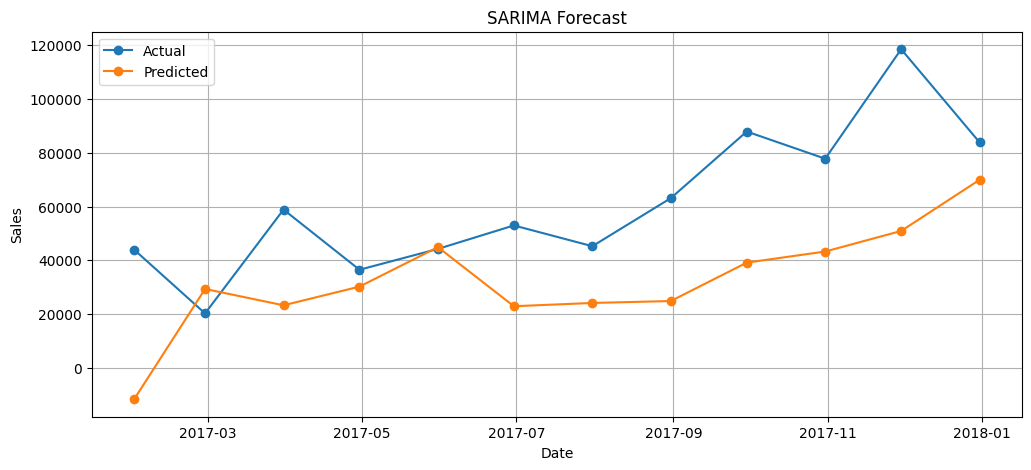

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    test["Order Date"],
    test["Sales"],
    marker="o",
    label="Actual"
)

plt.plot(
    test["Order Date"],
    predictions,
    marker="o",
    label="Predicted"
)

plt.title("SARIMA Forecast")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.legend()

plt.grid(True)

plt.show()